In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta. Las actividades marcadas como *expuestas* se realizan al aire libre: su duración depende además de un factor meteorológico común $F$ de media 1 y desviación típica 0.15 (si la temporada es mala, $F > 1$ y todas ellas se alargan a la vez). La duración de una actividad expuesta es $F \cdot X$, con $X$ normal de la media y desviación del cuadro; las no expuestas son normales independientes.

In [4]:
pregunta_1 = "1. Calcule la duración del proyecto y el camino crítico con las duraciones medias.  "
pregunta_2 = "2. Simule 10000 réplicas suponiendo todas las duraciones independientes (ignorando $F$) y obtenga la media, la desviación típica y la probabilidad de terminar en 25 semanas o menos.  "
pregunta_3 = "3. Repita la simulación con el factor común: en cada réplica se sortea un único valor de $F$ que multiplica a todas las actividades expuestas. Compare media, desviación típica, percentil 95 y P(T ≤ 25).  "
pregunta_4 = "4. ¿Por qué la correlación positiva aumenta la dispersión de la duración del proyecto aunque apenas cambie la media? ¿Qué ocurre con la criticidad de las rutas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule la duración del proyecto y el camino crítico con las duraciones medias.  

2. Simule 10000 réplicas suponiendo todas las duraciones independientes (ignorando $F$) y obtenga la media, la desviación típica y la probabilidad de terminar en 25 semanas o menos.  

3. Repita la simulación con el factor común: en cada réplica se sortea un único valor de $F$ que multiplica a todas las actividades expuestas. Compare media, desviación típica, percentil 95 y P(T ≤ 25).  

4. ¿Por qué la correlación positiva aumenta la dispersión de la duración del proyecto aunque apenas cambie la media? ¿Qué ocurre con la criticidad de las rutas?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation, exposed
    ('A'     , '---'      , 7       , 0.1               , 'sí'   ),
    ('B'     , '---'      , 5       , 0.1               , 'sí'   ),
    ('C'     , '---'      , 3       , 0.8               , 'no'   ),
    ('D'     , 'A,B,C'    , 4       , 0.5               , 'no'   ),
    ('E'     , 'A,B'      , 7       , 0.4               , 'sí'   ),
    ('F'     , 'B,C'      , 4       , 0.1               , 'no'   ),
    ('G'     , 'D,F'      , 6       , 0.2               , 'sí'   ),
    ('H'     , 'E,G'      , 4       , 1                 , 'no'   ),
    ('I'     , 'H'        , 2       , 0.8               , 'no'   ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation', 'exposed']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation,exposed
activity,,,,
A,---,7,0.1,sí
B,---,5,0.1,sí
C,---,3,0.8,no
D,"A,B,C",4,0.5,no
E,"A,B",7,0.4,sí
F,"B,C",4,0.1,no
G,"D,F",6,0.2,sí
H,"E,G",4,1.0,no
I,H,2,0.8,no


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
N, plazo, sigma_F = 10000, 25, 0.15
expuestas = datos_proyecto.index[datos_proyecto['exposed'] == 'sí'].tolist()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule la duración del proyecto y el camino crítico con las duraciones medias.  

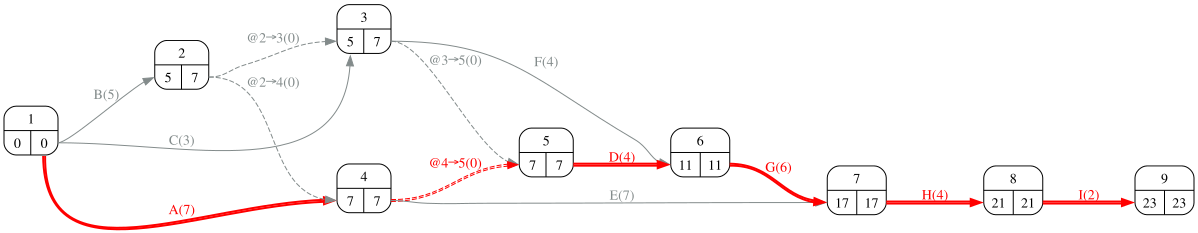

In [8]:
#| fig-cap: "Grafo PERT con el camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
path_matrix = proyecto.path_matrix(dummies=False)
duracion_media = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'Duración media del proyecto: {duracion_media} semanas. Actividades expuestas al factor común: {", ".join(expuestas)}.')

- Route_1 :	A, D, G, H, I <br> 

Duración media del proyecto: 23 semanas. Actividades expuestas al factor común: A, B, E, G.

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Simule 10000 réplicas suponiendo todas las duraciones independientes (ignorando $F$) y obtenga la media, la desviación típica y la probabilidad de terminar en 25 semanas o menos.  

In [11]:
rng = np.random.default_rng(7363)
mu, sigma = datos_proyecto['duration'].astype(float), datos_proyecto['standard_deviation'].astype(float)
X = pd.DataFrame(rng.normal(mu.values, sigma.values, size=(N, len(mu))), columns=mu.index).clip(lower=0)
T_indep = (X[path_matrix.columns] @ path_matrix.T).max(axis='columns')
resumen_indep = pd.Series({'media': T_indep.mean(), 'desviación típica': T_indep.std(), 'percentil 95': T_indep.quantile(0.95),
                           f'P(T ≤ {plazo}) (%)': (T_indep <= plazo).mean() * 100})
resumen_indep.round(3).to_frame('independientes').T

,media,desviación típica,percentil 95,P(T ≤ 25) (%)
independientes,23.038,1.399,25.329,91.88


## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Repita la simulación con el factor común: en cada réplica se sortea un único valor de $F$ que multiplica a todas las actividades expuestas. Compare media, desviación típica, percentil 95 y P(T ≤ 25).  

Se reutilizan las mismas duraciones normales $X$ y se multiplica cada fila (réplica) de las actividades expuestas por un valor de $F$ común a toda la fila. Así la única diferencia entre las dos simulaciones es la correlación introducida por $F$.

In [13]:
F = rng.normal(1.0, sigma_F, size=N).clip(min=0.5)
Xc = X.copy()
Xc[expuestas] = Xc[expuestas].mul(F, axis='rows')
duraciones_rutas_c = Xc[path_matrix.columns] @ path_matrix.T
T_corr = duraciones_rutas_c.max(axis='columns')
resumen_corr = pd.Series({'media': T_corr.mean(), 'desviación típica': T_corr.std(), 'percentil 95': T_corr.quantile(0.95),
                          f'P(T ≤ {plazo}) (%)': (T_corr <= plazo).mean() * 100})
pd.DataFrame({'independientes': resumen_indep, 'con factor común': resumen_corr}).round(3)

,independientes,con factor común
media,23.038,23.011
desviación típica,1.399,2.375
percentil 95,25.329,26.932
P(T ≤ 25) (%),91.880,80.160


In [14]:
#| tbl-cap: "Correlación entre las duraciones de dos actividades expuestas"
#| label: tbl-correlacion
a1, a2 = expuestas[:2]
pd.DataFrame({'independientes': [X[a1].corr(X[a2])], 'con factor común': [Xc[a1].corr(Xc[a2])]}, index=[f'corr({a1}, {a2})']).round(3)

,independientes,con factor común
"corr(A, B)",-0.003,0.986


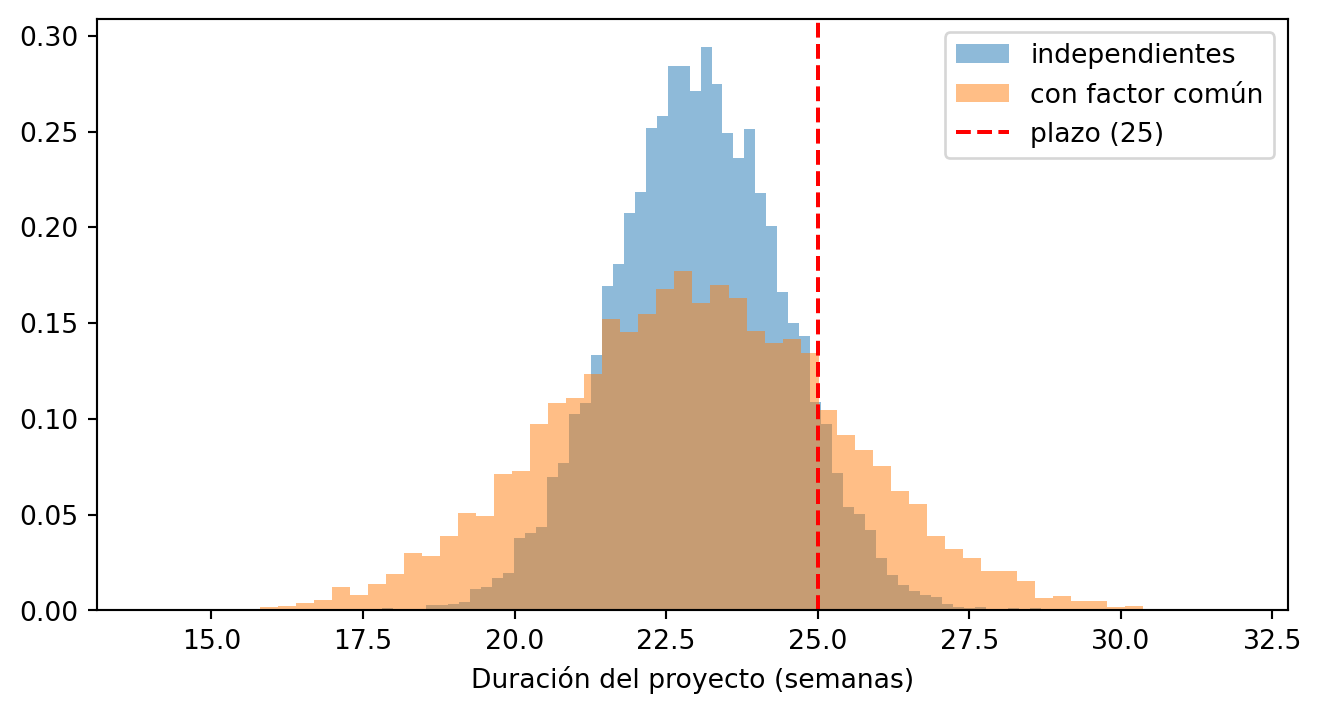

In [15]:
#| fig-cap: "Distribución de la duración con y sin factor común"
#| label: fig-histograma
from matplotlib import pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(T_indep, bins=60, density=True, alpha=0.5, label='independientes')
ax.hist(T_corr, bins=60, density=True, alpha=0.5, label='con factor común')
ax.axvline(plazo, color='red', linestyle='--', label=f'plazo ({plazo})')
ax.set_xlabel('Duración del proyecto (semanas)'); ax.legend(); plt.show()

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. ¿Por qué la correlación positiva aumenta la dispersión de la duración del proyecto aunque apenas cambie la media? ¿Qué ocurre con la criticidad de las rutas?  

In [17]:
ruta_critica_mc = duraciones_rutas_c.idxmax(axis='columns')
criticidad_corr = (ruta_critica_mc.value_counts(normalize=True) * 100).reindex(path_matrix.index, fill_value=0.0)
criticidad_indep = ((X[path_matrix.columns] @ path_matrix.T).idxmax(axis='columns').value_counts(normalize=True) * 100).reindex(path_matrix.index, fill_value=0.0)
pd.DataFrame({'actividades': path_matrix.apply(lambda f: ' - '.join(f.index[f == 1]), axis=1),
              'criticidad indep. (%)': criticidad_indep, 'criticidad con F (%)': criticidad_corr}).round(1)

,actividades,criticidad indep. (%),criticidad con F (%)
Route_1,A - D - G - H - I,100.0,99.8
Route_2,A - E - H - I,0.0,0.0
Route_3,B - D - G - H - I,0.0,0.0
Route_4,B - D - G - H - I,0.0,0.0
Route_5,B - E - H - I,0.0,0.0
Route_6,B - F - G - H - I,0.0,0.0
Route_7,C - D - G - H - I,0.0,0.0
Route_8,C - F - G - H - I,0.0,0.2


La varianza de una suma de variables correlacionadas positivamente es mayor que la suma de sus varianzas (se añaden los términos $2\,\mathrm{cov}$): cuando $F$ sale alto, todas las actividades expuestas se alargan a la vez y no se compensan unas con otras. La media casi no cambia (la de $F$ es 1), pero las colas se ensanchan: el percentil 95 sube y la probabilidad de cumplir el plazo baja. Las rutas con más actividades expuestas ganan criticidad. Suponer independencia, como hace el PERT clásico, es optimista en presencia de causas comunes de retraso.